In [3]:
#imports and basic data checks
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
df = pd.read_csv("TeamStatisticsExtended.csv")
df.shape
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79724 entries, 0 to 79723
Columns: 104 entries, gameId to opponentOffensiveReboundPercentage
dtypes: float64(72), int64(24), object(8)
memory usage: 63.3+ MB


In [4]:
#Variable and data-type audit

# data frame of interesting features to use in the analysis
df2 = df[["win","teamScore","opponentScore","threePointersMade","threePointersAttempted","turnovers","assistPercentage",
                      "assistToTurnoverRatio","reboundPercentage","pointsOffTurnovers","percentPoints3Point","percentPointsOffTurnovers","threePointersPercentage","gameDateTimeEst","gameType"]]
#building a summary table of important data information
summary = { 'Name' : ["win","teamScore","opponentScore","threePointersMade","threePointersAttempted","turnovers","assistPercentage",
                      "assistToTurnoverRatio","reboundPercentage","pointsOffTurnovers","percentPoints3Point","percentPointsOffTurnovers"]
           , 'Role' : ["outcome variable of interest","possible variable of interest, shows offensive success","possible variable of interest, shows defensive success","possible predictor of winning","possible predictor of winning","possible predictor of winning","possible predictor of winning",
                      "possible predictor of winning","possible predictor of winning","possible predictor of winning","possible predictor of winning","possible predictor of winning"],
           'Data Type' : ["binary","integer","integer","integer","integer","integer","ratio",
                      "ratio","ratio","integer","ratio","ratio"]
           , 'Transformation Needed' : ["None","None","None","None","None","None","None",
                      "None","None","None","None","None"]
}
summary_df = pd.DataFrame(summary)
summary_df

,Name,Role,Data Type,Transformation Needed
0,win,outcome variable of interest,binary,None
1,teamScore,"possible variable of interest, shows offensive...",integer,None
2,opponentScore,"possible variable of interest, shows defensive...",integer,None
3,threePointersMade,possible predictor of winning,integer,None
4,threePointersAttempted,possible predictor of winning,integer,None
5,turnovers,possible predictor of winning,integer,None
6,assistPercentage,possible predictor of winning,ratio,None
7,assistToTurnoverRatio,possible predictor of winning,ratio,None
8,reboundPercentage,possible predictor of winning,ratio,None
9,pointsOffTurnovers,possible predictor of winning,integer,None


In [5]:
# Perform project-relevant data-quality checks here.
# Possible examples:
# df.isna().sum()
# df.duplicated().sum()
# df.describe()
# df["category"].value_counts()
# domain-specific validity checks

# Data-quality evidence checks and deeper information about our data
print(df2.isna().sum())
print(df2.duplicated().sum())
print(df2.describe())

win                              0
teamScore                        0
opponentScore                    0
threePointersMade                0
threePointersAttempted           0
turnovers                        0
assistPercentage                 0
assistToTurnoverRatio            0
reboundPercentage            14457
pointsOffTurnovers               0
percentPoints3Point              0
percentPointsOffTurnovers        0
threePointersPercentage          0
gameDateTimeEst                  0
gameType                      7510
dtype: int64
0
                win     teamScore  opponentScore  threePointersMade  \
count  79724.000000  79724.000000   79724.000000       79724.000000   
mean       0.500000    102.141676     102.141676           8.141563   
std        0.500003     14.114008      14.114008           4.468000   
min        0.000000      0.000000       0.000000           0.000000   
25%        0.000000     92.000000      92.000000           5.000000   
50%        0.500000    102.000000 

**Data-quality decisions and justification:**

1. My first data quality decision was to use this data set. It does not have the data for the exact question I was hoping to answer, but it can answer similar questions with very high quality data that I feel would give more reliable results than other potential data sources I had due to its robustness and also its completeness.
2. We only have 2 categories with missing values, one is reboundPercentage which I will leave as it is for now. I would think that we could imput that manually with the raw rebound numbers later on if need be, and as it stands I do not want to blindly impute values that worsen what is an overall very very clean and good data set. For GameType, these will be handled below as I have decided to filter out some types of games, like preseason, all star games etc, and along with it the missing values will be lost as well.
 


In [6]:
#converting date time to year for later analysis :)
df2["year"] = df2["gameDateTimeEst"].astype(str).str[:4].astype(int)
df2.drop(columns=["gameDateTimeEst"], inplace=True)

# keep only regular season and playoff games
game_types = ["Regular Season", "Playoffs"]
df2 = df2[df2["gameType"].isin(game_types)].copy()


/var/folders/ls/6mg_6lk95hndnytgm0rp2_vc0000gn/T/ipykernel_6284/345691157.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2["year"] = df2["gameDateTimeEst"].astype(str).str[:4].astype(int)
/var/folders/ls/6mg_6lk95hndnytgm0rp2_vc0000gn/T/ipykernel_6284/345691157.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2.drop(columns=["gameDateTimeEst"], inplace=True)


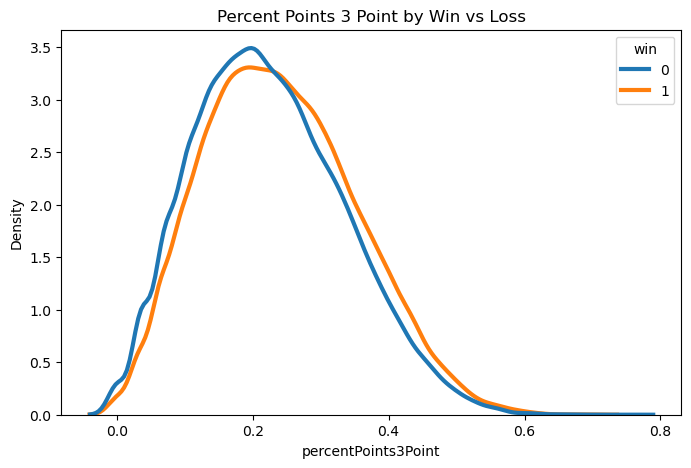

0.016478595985361


In [7]:
# Question 1: Is the percent of points coming from 3 pointers associated with winning?
difference = df2[df2["win"] == 1]["percentPoints3Point"].mean() - df2[df2["win"] == 0]["percentPoints3Point"].mean()
fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(data=df, x="percentPoints3Point", hue="win",
            common_norm=False, fill=False, linewidth=3, ax=ax)
ax.set_title("Percent Points 3 Point by Win vs Loss")
plt.show()
print(difference)

**Question 1 interpretation and limitation: My interpretation of this is there is appears to be a difference in that the winning team has a slightly higher KDE graph for percent Points coming from 3 pointers. This could suggest that teams should prioritize three pointers, but more specfically high quality 3 pointers that are likely to result in points. A limitation of this is that you can visually see the difference but it does not quantify the difference into a percentage or a rule of thumb that could be applied to strategy going into games. Across all recorded NBA games, there is a difference of 1.647% in percent of points coming from 3 pointers between the winning and losing teams. **

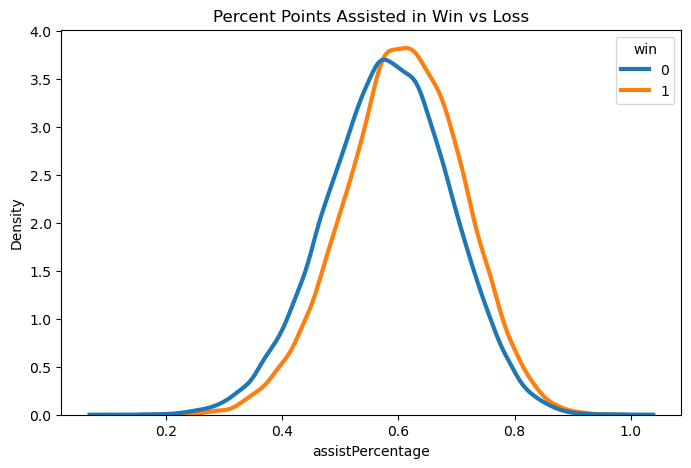

0.02790007763114133


In [8]:
# Question 2: Is the percent of points coming from assists associated with winning?

differenceAssists = df2[df2["win"] == 1]["assistPercentage"].mean() - df2[df2["win"] == 0]["assistPercentage"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(data=df, x="assistPercentage", hue="win",
            common_norm=False, fill=False, linewidth=3, ax=ax)
ax.set_title("Percent Points Assisted in Win vs Loss")
plt.show()
print(differenceAssists)

**Question 2 interpretation and limitation: This shows a clear difference in the percent of points a team scores coming from assists whether if they win or lose. I believe this shows that playing as a team and passing the ball is a more effective strategy to win than not playing as cohesively. There is a 2.790% difference in the percent assists between the teams that win and lose. A shortcoming of this again is that we can clearly visually see the difference but we cannot quantify it in how much more likely you are to win if you prioritize passing as a team compared to scoring the ball yourself. **

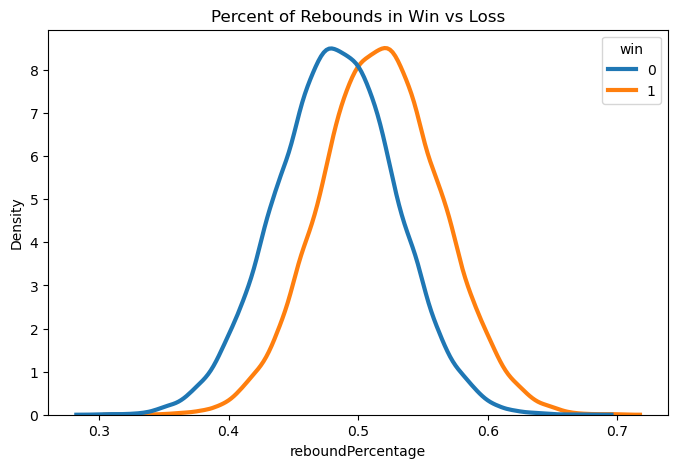

0.034957938530320365


In [9]:
# Question 3: Is the percent of rebounds secured in the game associated with winning?

differenceRebounds = df2[df2["win"] == 1]["reboundPercentage"].mean() - df2[df2["win"] == 0]["reboundPercentage"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(data=df, x="reboundPercentage", hue="win",
            common_norm=False, fill=False, linewidth=3, ax=ax)
ax.set_title("Percent of Rebounds in Win vs Loss")
plt.show()
print(differenceRebounds)

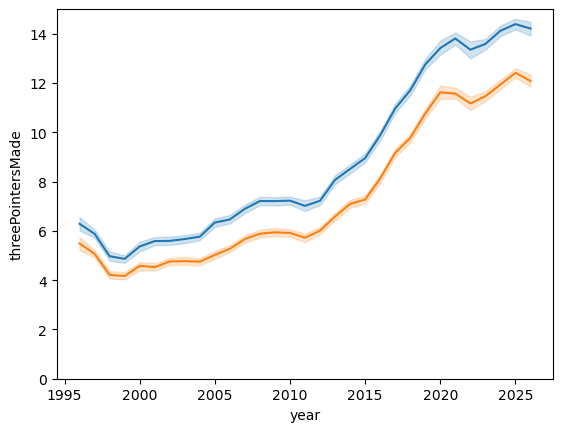

In [10]:
# Question 4: How has the 3 pointer evolved over time, and is there a difference between winning and losing teams?
ax = sns.lineplot(data=df2[df2["win"] == 1],x="year",y="threePointersMade")
sns.lineplot(data=df2[df2["win"] == 0],x="year",y="threePointersMade")
ax.set_ylim(0,15)
plt.show()

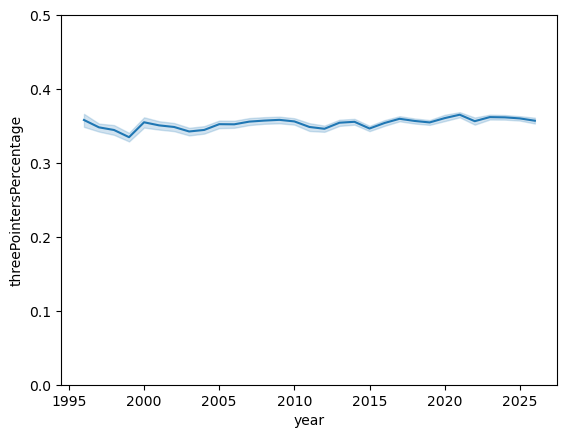

In [11]:
#Question 5: Has 3 point percentage changed over time?
ax = sns.lineplot(data=df2,x="year",y="threePointersPercentage")
ax.set_ylim(0,.5)
plt.show()

                                    win  teamScore  opponentScore  \
win                        1.000000e+00   0.399000      -0.399000   
teamScore                  3.990000e-01   1.000000       0.511293   
opponentScore             -3.990000e-01   0.511293       1.000000   
threePointersMade          1.628072e-01   0.626125       0.398087   
threePointersAttempted     1.921825e-03   0.489321       0.451154   
turnovers                 -1.199181e-01  -0.164218      -0.015670   
assistPercentage           1.323008e-01   0.118982      -0.030675   
assistToTurnoverRatio      2.442229e-01   0.442677       0.134700   
reboundPercentage          3.524703e-01   0.214402      -0.214217   
pointsOffTurnovers         2.237697e-01   0.246354      -0.035082   
percentPoints3Point        7.519510e-02   0.435394       0.314379   
percentPointsOffTurnovers  7.557552e-02  -0.126796      -0.225829   
threePointersPercentage    2.879781e-01   0.392691       0.051567   
year                      -3.18625

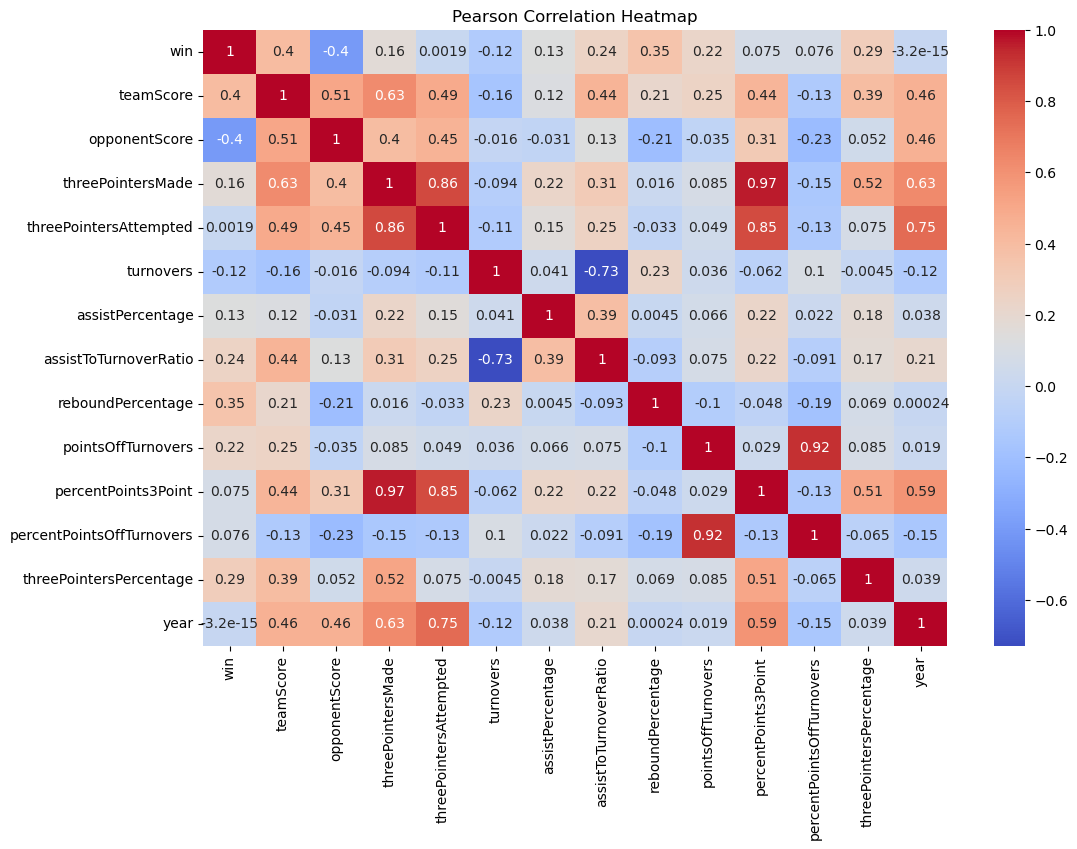

In [12]:
#pearson correlation heatmap of our variables of interest 
df3 = df2.drop(columns='gameType')
pearson_corr = df3.corr(method='pearson')
print(pearson_corr)
plt.figure(figsize=(12, 8))
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm')
plt.title("Pearson Correlation Heatmap")
plt.show()



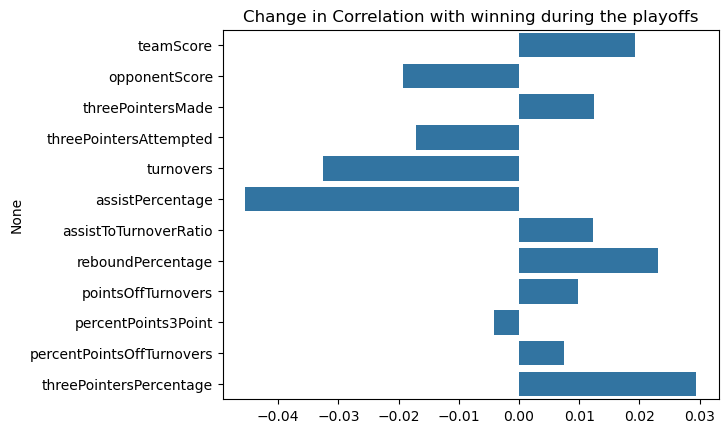

In [17]:
#difference between regular season and playoffs correlation to winning
rs = df2[df2["gameType"] == "Regular Season"]
po = df2[df2["gameType"] == "Playoffs"]

df3 = df2.drop(columns=["win", "gameType", "year"]).columns

diff = po[df3].corrwith(po["win"]) - rs[df3].corrwith(rs["win"])

sns.barplot(x=diff.values, y=diff.index)
plt.title("Change in Correlation with winning during the playoffs")
plt.show()